In [1]:
import os
import urllib.request
import gzip
import shutil
import pandas as pd
import re
import fasttext
import random
import spacy
from spacy.util import compile_infix_regex
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import calamancy
import matplotlib.pyplot as plt
# books_path = './books/outputv3'
books_path = './bloom-text'
# books_path = './letsread-text'
# books_path = './storyweaver-text'
# books_path = './storyweaver-text2'
# books_path = './extra-books'
# books_path = './lola-basyang-text'
# books_path = './lola-basyang-text-2'
# books_path = './lola-basyang-text-3'

In [109]:
def paragraphs_to_dataframe(text: str, filename: str) -> pd.DataFrame:
    """
    Splits raw text into paragraphs and returns a DataFrame
    with each paragraph in a separate row.
    Adds filename info for tracking.
    """
    paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]

    df = pd.DataFrame(paragraphs, columns=["sentence"])
    bookRange = range(1, len(df) + 1)
    df.insert(0, "filename", filename)  # keep track of source file
    df.insert(1, "year_published", filename[0:4])
    df.insert(2, "sentence_id", bookRange)
    return df


# Example usage
books_path = './bloom-text'
folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
final_df = pd.concat(all_dfs, ignore_index=True)
print(final_df)

                          filename year_published  sentence_id  \
0     2025JosueAngTagapamahala.txt           2025            1   
1     2025JosueAngTagapamahala.txt           2025            2   
2     2025JosueAngTagapamahala.txt           2025            3   
3     2025JosueAngTagapamahala.txt           2025            4   
4     2025JosueAngTagapamahala.txt           2025            5   
...                            ...            ...          ...   
3276            2025ApatnaTaon.txt           2025           57   
3277            2025ApatnaTaon.txt           2025           58   
3278            2025ApatnaTaon.txt           2025           59   
3279            2025ApatnaTaon.txt           2025           60   
3280            2025ApatnaTaon.txt           2025           61   

                                               sentence  
0                                   Patay na si Moises.  
1     Alam ni\nJosue na siya ay pinili ng Diyos\nna ...  
2     Bago hinanda ni Josue ang\n

In [110]:
nlp = calamancy.load("tl_calamancy_trf-0.2.0")


/opt/anaconda3/envs/nlp_env/lib/python3.11/site-packages/spacy/util.py:930: UserWarning: [W094] Model 'tl_calamancy_trf' (0.2.0) specifies an under-constrained spaCy version requirement: >=3.8.3. This can lead to compatibility problems with older versions, or as new spaCy versions are released, because the model may say it's compatible when it's not. Consider changing the "spacy_version" in your meta.json to a version range, with a lower and upper pin. For example: >=3.8.7,<3.9.0
  warnings.warn(warn_msg)


In [111]:
def annotate_text(text: str):
    """
    Run POS tagging and NER.

    Returns
    -------
    doc : Calamancy Doc
        The annotated document.
    annotations : list of dict
        Token-level annotations with POS and NER labels.
    """

    doc = nlp(text)

    annotations = []

    for token in doc:
        annotations.append({
            "token": token.text,
            "pos": token.pos_,
            "entity": token.ent_type_ if token.ent_type_ else "O"
        })

    return doc, annotations

In [112]:
text = "Tagapag_alaga si Juan de la Cruz isang mag_aaral na nag_aaral - sa Manila"
annotate_text(text)

(Tagapag_alaga si Juan de la Cruz isang mag_aaral na nag_aaral - sa Manila,
 [{'token': 'Tagapag_alaga', 'pos': 'VERB', 'entity': 'O'},
  {'token': 'si', 'pos': 'DET', 'entity': 'O'},
  {'token': 'Juan', 'pos': 'PROPN', 'entity': 'PER'},
  {'token': 'de', 'pos': 'PROPN', 'entity': 'PER'},
  {'token': 'la', 'pos': 'PROPN', 'entity': 'PER'},
  {'token': 'Cruz', 'pos': 'PROPN', 'entity': 'PER'},
  {'token': 'isang', 'pos': 'NUM', 'entity': 'O'},
  {'token': 'mag_aaral', 'pos': 'NOUN', 'entity': 'O'},
  {'token': 'na', 'pos': 'PART', 'entity': 'O'},
  {'token': 'nag_aaral', 'pos': 'VERB', 'entity': 'O'},
  {'token': '-', 'pos': 'PUNCT', 'entity': 'O'},
  {'token': 'sa', 'pos': 'ADP', 'entity': 'O'},
  {'token': 'Manila', 'pos': 'PROPN', 'entity': 'LOC'}])

In [113]:
# CORPUS_NO_LEMMA = "tl_no_lemma3.txt"
# CORPUS_NO_LEMMA = 'tl_no_lemma_bloom'

def tokenize_text(text: str) -> str:
    doc = nlp(text)
    return doc
    # tokens = [token.text for token in doc if not token.is_space]
    # return " ".join(tokens)

def clean_text(text: str) -> str:
    """Lowercase, remove punctuation, lemmatize, remove stopwords."""
    text = text.lower()
    # text = re.sub(r'[^\w\s]', ' ', text)  # remove punctuation, including hyphen-
    text = re.sub(r'[^\w\s-]', ' ', text) # remove punctuation excluding hyphen
    text = re.sub(r'\n', ' ', text) # replace newline wit space
    text = re.sub(r' +', ' ', text) # remove extraspaces
    text = text.strip() # remove leading and trailing whitespace
    # text = re.sub(r"^\s+", "", text) # remove leading spaces
    
    # doc = nlp(text)
    # lemmas = [token.lemma_ for token in doc if not token.is_space]
    # return " ".join(filtered)
    return text

# final_df['tokenized'] = final_df['sentence'].apply(tokenize_text)
# final_df['processed'] = final_df['sentence'].apply(clean_text)

In [114]:
# final_df['tokenized'] = final_df['sentence'].apply(tokenize_text)
final_df['processed'] = final_df['sentence'].apply(clean_text)

In [115]:
final_df['processed'].replace(['', 'null'], np.nan, inplace=True)
final_df.dropna(subset=['processed'], inplace=True)


/var/folders/rn/4hgc0wjn3csd__xbfr5n92jr0000gn/T/ipykernel_8325/1377684116.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df['processed'].replace(['', 'null'], np.nan, inplace=True)


In [116]:
final_df

,filename,year_published,sentence_id,sentence,processed
0,2025JosueAngTagapamahala.txt,2025,1,Patay na si Moises.,patay na si moises
1,2025JosueAngTagapamahala.txt,2025,2,Alam ni\nJosue na siya ay pinili ng Diyos\nna ...,alam ni josue na siya ay pinili ng diyos na ma...
2,2025JosueAngTagapamahala.txt,2025,3,"Bago hinanda ni Josue ang\nkanyang kawalan, hi...",bago hinanda ni josue ang kanyang kawalan hina...
3,2025JosueAngTagapamahala.txt,2025,4,Ang Diyos ay nangako kay Josue na\nsiya ay mag...,ang diyos ay nangako kay josue na siya ay magt...
4,2025JosueAngTagapamahala.txt,2025,5,Nangako ang mga\nIsraelita na sumunod kay\nJos...,nangako ang mga israelita na sumunod kay josue...
...,...,...,...,...,...
3276,2025ApatnaTaon.txt,2025,57,Nakalimotan nila ang mga\nbagay na ginawa ng D...,nakalimotan nila ang mga bagay na ginawa ng di...
3277,2025ApatnaTaon.txt,2025,58,Umiyak sila at hamanda\nupang babalik sa Ehipto.,umiyak sila at hamanda upang babalik sa ehipto
3278,2025ApatnaTaon.txt,2025,59,Sinikap nila na patayin si Moises. \n \nNiligt...,sinikap nila na patayin si moises niligtas ng ...
3279,2025ApatnaTaon.txt,2025,60,"Sinabi niya sa mga\ntao, “Apat na pong taon ka...",sinabi niya sa mga tao apat na pong taon kayo ...


In [117]:
final_df.to_csv('tl_bloom_all.csv', index=False)
final_df[['filename', 'year_published', 'processed']].to_csv('tl_no_lemma_bloom.csv', index=False)
final_df[['filename', 'year_published', 'sentence']].to_csv('tl_orig_bloom.csv', index=False)

In [118]:
bloom_no_lemma = pd.read_csv('tl_no_lemma_bloom.csv')
years_list = bloom_no_lemma['year_published']
filenames_list = bloom_no_lemma['filename']
bloom_no_lemma

,filename,year_published,processed
0,2025JosueAngTagapamahala.txt,2025,patay na si moises
1,2025JosueAngTagapamahala.txt,2025,alam ni josue na siya ay pinili ng diyos na ma...
2,2025JosueAngTagapamahala.txt,2025,bago hinanda ni josue ang kanyang kawalan hina...
3,2025JosueAngTagapamahala.txt,2025,ang diyos ay nangako kay josue na siya ay magt...
4,2025JosueAngTagapamahala.txt,2025,nangako ang mga israelita na sumunod kay josue...
...,...,...,...
3276,2025ApatnaTaon.txt,2025,nakalimotan nila ang mga bagay na ginawa ng di...
3277,2025ApatnaTaon.txt,2025,umiyak sila at hamanda upang babalik sa ehipto
3278,2025ApatnaTaon.txt,2025,sinikap nila na patayin si moises niligtas ng ...
3279,2025ApatnaTaon.txt,2025,sinabi niya sa mga tao apat na pong taon kayo ...


In [119]:
bloom_orig = pd.read_csv('tl_orig_bloom.csv')
bloom_orig

,filename,year_published,sentence
0,2025JosueAngTagapamahala.txt,2025,Patay na si Moises.
1,2025JosueAngTagapamahala.txt,2025,Alam ni\nJosue na siya ay pinili ng Diyos\nna ...
2,2025JosueAngTagapamahala.txt,2025,"Bago hinanda ni Josue ang\nkanyang kawalan, hi..."
3,2025JosueAngTagapamahala.txt,2025,Ang Diyos ay nangako kay Josue na\nsiya ay mag...
4,2025JosueAngTagapamahala.txt,2025,Nangako ang mga\nIsraelita na sumunod kay\nJos...
...,...,...,...
3276,2025ApatnaTaon.txt,2025,Nakalimotan nila ang mga\nbagay na ginawa ng D...
3277,2025ApatnaTaon.txt,2025,Umiyak sila at hamanda\nupang babalik sa Ehipto.
3278,2025ApatnaTaon.txt,2025,Sinikap nila na patayin si Moises. \n \nNiligt...
3279,2025ApatnaTaon.txt,2025,"Sinabi niya sa mga\ntao, “Apat na pong taon ka..."


In [120]:
len(years_list)

3281

# Lets Read Processing (no null)

In [121]:
books_path = './letsread-text'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
letsread_df = pd.concat(all_dfs, ignore_index=True)
print(letsread_df)

                filename year_published  sentence_id  \
0      2019alitaptap.txt           2019            1   
1      2019alitaptap.txt           2019            2   
2      2019alitaptap.txt           2019            3   
3      2019alitaptap.txt           2019            4   
4      2019alitaptap.txt           2019            5   
...                  ...            ...          ...   
2884  2022bilangmoru.txt           2022          160   
2885  2022bilangmoru.txt           2022          161   
2886  2022bilangmoru.txt           2022          162   
2887  2022bilangmoru.txt           2022          163   
2888  2022bilangmoru.txt           2022          164   

                                               sentence  
0                Alitaptap, Alitaptap!\nHalina! Halina!  
1     Katulad ng mga matang kumikindat!\nHalina’t ku...  
2                      Sa dilim!\nAlitaptap! Alitaptap!  
3                 Halina, halina!\nAng araw ay sisikat.  
4                                   D

In [122]:
# letsread_df['tokenized'] = letsread_df['sentence'].apply(tokenize_text)
letsread_df['processed'] = letsread_df['sentence'].apply(clean_text)

In [123]:
letsread_df.to_csv('tl_letsread_all.csv', index=False)
letsread_df[['filename', 'year_published', 'processed']].to_csv('tl_no_lemma_letsread.csv', index=False)
letsread_df[['filename', 'year_published', 'sentence']].to_csv('tl_orig_letsread.csv', index=False)
letsread_years_list = letsread_df['year_published']
letsread_filenames_list = letsread_df['filename']

In [124]:
letsread_df

,filename,year_published,sentence_id,sentence,processed
0,2019alitaptap.txt,2019,1,"Alitaptap, Alitaptap!\nHalina! Halina!",alitaptap alitaptap halina halina
1,2019alitaptap.txt,2019,2,Katulad ng mga matang kumikindat!\nHalina’t ku...,katulad ng mga matang kumikindat halina t kumi...
2,2019alitaptap.txt,2019,3,Sa dilim!\nAlitaptap! Alitaptap!,sa dilim alitaptap alitaptap
3,2019alitaptap.txt,2019,4,"Halina, halina!\nAng araw ay sisikat.",halina halina ang araw ay sisikat
4,2019alitaptap.txt,2019,5,Darating ang umaga.,darating ang umaga
...,...,...,...,...,...
2884,2022bilangmoru.txt,2022,160,"Tumingin din ang guro, at ngumiti siya sa kany...",tumingin din ang guro at ngumiti siya sa kanya...
2885,2022bilangmoru.txt,2022,161,Masaya siyang ngumiti pabalik.,masaya siyang ngumiti pabalik
2886,2022bilangmoru.txt,2022,162,Si Moru ay nasa paaralan muli.,si moru ay nasa paaralan muli
2887,2022bilangmoru.txt,2022,163,Sa pagkakataong ito ay lalo siyang natuto.,sa pagkakataong ito ay lalo siyang natuto


# Storyweaver 1 Processing (must drop nulls)

In [125]:
books_path = './storyweaver-text'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
storyweaver1_df = pd.concat(all_dfs, ignore_index=True)
print(storyweaver1_df)

                  filename year_published  sentence_id  \
0     2007akingkatawan.txt           2007            1   
1     2007akingkatawan.txt           2007            2   
2     2007akingkatawan.txt           2007            3   
3     2007akingkatawan.txt           2007            4   
4     2007akingkatawan.txt           2007            5   
...                    ...            ...          ...   
2368      2019paruparo.txt           2019            3   
2369      2019paruparo.txt           2019            4   
2370      2019paruparo.txt           2019            5   
2371      2019paruparo.txt           2019            6   
2372      2019paruparo.txt           2019            7   

                                   sentence  
0                Nakatatakbo ako gamit ito.  
1                Nakatatalon ako gamit ito.  
2                Nakasasayaw ako gamit ito.  
3               Nakalalangoy ako gamit ito.  
4               Nakalalaktaw ako gamit ito.  
...                        

In [126]:
# storyweaver1_df['tokenized'] = storyweaver1_df['sentence'].apply(tokenize_text)
storyweaver1_df['processed'] = storyweaver1_df['sentence'].apply(clean_text)

In [127]:
storyweaver1_df['processed'].replace(['', 'null'], np.nan, inplace=True)
storyweaver1_df.dropna(subset=['processed'], inplace=True)


/var/folders/rn/4hgc0wjn3csd__xbfr5n92jr0000gn/T/ipykernel_8325/1651213008.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  storyweaver1_df['processed'].replace(['', 'null'], np.nan, inplace=True)


In [128]:
storyweaver1_df

,filename,year_published,sentence_id,sentence,processed
0,2007akingkatawan.txt,2007,1,Nakatatakbo ako gamit ito.,nakatatakbo ako gamit ito
1,2007akingkatawan.txt,2007,2,Nakatatalon ako gamit ito.,nakatatalon ako gamit ito
2,2007akingkatawan.txt,2007,3,Nakasasayaw ako gamit ito.,nakasasayaw ako gamit ito
3,2007akingkatawan.txt,2007,4,Nakalalangoy ako gamit ito.,nakalalangoy ako gamit ito
4,2007akingkatawan.txt,2007,5,Nakalalaktaw ako gamit ito.,nakalalaktaw ako gamit ito
...,...,...,...,...,...
2368,2019paruparo.txt,2019,3,Ang lagsing ay mas maliit kaysa loro.,ang lagsing ay mas maliit kaysa loro
2369,2019paruparo.txt,2019,4,Ang loro ay mas maliit\nkaysa kuwágo.,ang loro ay mas maliit kaysa kuwágo
2370,2019paruparo.txt,2019,5,Kaláw ang pinaka-malaki.,kaláw ang pinaka-malaki
2371,2019paruparo.txt,2019,6,Paruparó ang pinaka-maliit.,paruparó ang pinaka-maliit


In [129]:
storyweaver1_df.to_csv('tl_storyweaver1_all.csv', index=False)
storyweaver1_df[['filename','year_published', 'processed']].to_csv('tl_no_lemma_storyweaver1.csv', index=False)
storyweaver1_df[['filename','year_published', 'sentence']].to_csv('tl_orig_storyweaver1.csv', index=False)
# storyweaver1_df = pd.read_csv('tl_no_lemma_storyweaver1.csv')
storyweaver1_years_list = storyweaver1_df['year_published']
storyweaver1_filenames_list = storyweaver1_df['filename']

In [130]:
storyweaver1_df

,filename,year_published,sentence_id,sentence,processed
0,2007akingkatawan.txt,2007,1,Nakatatakbo ako gamit ito.,nakatatakbo ako gamit ito
1,2007akingkatawan.txt,2007,2,Nakatatalon ako gamit ito.,nakatatalon ako gamit ito
2,2007akingkatawan.txt,2007,3,Nakasasayaw ako gamit ito.,nakasasayaw ako gamit ito
3,2007akingkatawan.txt,2007,4,Nakalalangoy ako gamit ito.,nakalalangoy ako gamit ito
4,2007akingkatawan.txt,2007,5,Nakalalaktaw ako gamit ito.,nakalalaktaw ako gamit ito
...,...,...,...,...,...
2368,2019paruparo.txt,2019,3,Ang lagsing ay mas maliit kaysa loro.,ang lagsing ay mas maliit kaysa loro
2369,2019paruparo.txt,2019,4,Ang loro ay mas maliit\nkaysa kuwágo.,ang loro ay mas maliit kaysa kuwágo
2370,2019paruparo.txt,2019,5,Kaláw ang pinaka-malaki.,kaláw ang pinaka-malaki
2371,2019paruparo.txt,2019,6,Paruparó ang pinaka-maliit.,paruparó ang pinaka-maliit


# Storyweaver 2 Processing

In [131]:
books_path = './storyweaver-text2'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
storyweaver2_df = pd.concat(all_dfs, ignore_index=True)
print(storyweaver2_df)

                   filename year_published  sentence_id  \
0         2018tamadmama.txt           2018            1   
1         2018tamadmama.txt           2018            2   
2         2018tamadmama.txt           2018            3   
3         2018tamadmama.txt           2018            4   
4         2018tamadmama.txt           2018            5   
...                     ...            ...          ...   
4046  2015malinisnapusa.txt           2015           21   
4047  2015malinisnapusa.txt           2015           22   
4048  2015malinisnapusa.txt           2015           23   
4049  2015malinisnapusa.txt           2015           24   
4050  2015malinisnapusa.txt           2015           25   

                                               sentence  
0                                         Katok, katok!  
1                           Binuksan ni Amma ang pinto.  
2                                         “Raghu Mama!”  
3     “Sina Ami at Soni \nay umiyak nang bigyan nila...  
4

In [132]:
# storyweaver2_df['tokenized'] = storyweaver2_df['paragraph'].apply(tokenize_text)
storyweaver2_df['processed'] = storyweaver2_df['sentence'].apply(clean_text)

In [133]:
storyweaver2_df['processed'].replace(['', 'null'], np.nan, inplace=True)
storyweaver2_df.dropna(subset=['processed'], inplace=True)


/var/folders/rn/4hgc0wjn3csd__xbfr5n92jr0000gn/T/ipykernel_8325/1131262025.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  storyweaver2_df['processed'].replace(['', 'null'], np.nan, inplace=True)


In [134]:
storyweaver2_df

,filename,year_published,sentence_id,sentence,processed
0,2018tamadmama.txt,2018,1,"Katok, katok!",katok katok
1,2018tamadmama.txt,2018,2,Binuksan ni Amma ang pinto.,binuksan ni amma ang pinto
2,2018tamadmama.txt,2018,3,“Raghu Mama!”,raghu mama
3,2018tamadmama.txt,2018,4,“Sina Ami at Soni \nay umiyak nang bigyan nila...,sina ami at soni ay umiyak nang bigyan nila si...
4,2018tamadmama.txt,2018,5,Si Raghu Mama ay ang kaisa-isang lalaking kapa...,si raghu mama ay ang kaisa-isang lalaking kapa...
...,...,...,...,...,...
4046,2015malinisnapusa.txt,2015,21,Pero mahimbing na akong natutulog sa kama.,pero mahimbing na akong natutulog sa kama
4047,2015malinisnapusa.txt,2015,22,Nakakapagsalita ang buntot!\n \nAlam mo bang n...,nakakapagsalita ang buntot alam mo bang nakaka...
4048,2015malinisnapusa.txt,2015,23,Iwinawagwag ng aso ang kanyang\nbuntot kapag m...,iwinawagwag ng aso ang kanyang buntot kapag ma...
4049,2015malinisnapusa.txt,2015,24,Tumitirik\nnaman ang buntot ng pusa kapag\ngal...,tumitirik naman ang buntot ng pusa kapag galit...


In [135]:
storyweaver2_df.to_csv('tl_storyweaver2_all.csv', index=False)
storyweaver2_df[['filename','year_published', 'processed']].to_csv('tl_no_lemma_storyweaver2.csv', index=False)
storyweaver2_df[['filename','year_published', 'sentence']].to_csv('tl_orig_storyweaver2.csv', index=False)
# storyweaver2_df = pd.read_csv('tl_no_lemma_storyweaver2.csv')
storyweaver2_years_list = storyweaver2_df['year_published']
storyweaver2_filenames_list = storyweaver2_df['filename']

In [136]:
storyweaver2_df

,filename,year_published,sentence_id,sentence,processed
0,2018tamadmama.txt,2018,1,"Katok, katok!",katok katok
1,2018tamadmama.txt,2018,2,Binuksan ni Amma ang pinto.,binuksan ni amma ang pinto
2,2018tamadmama.txt,2018,3,“Raghu Mama!”,raghu mama
3,2018tamadmama.txt,2018,4,“Sina Ami at Soni \nay umiyak nang bigyan nila...,sina ami at soni ay umiyak nang bigyan nila si...
4,2018tamadmama.txt,2018,5,Si Raghu Mama ay ang kaisa-isang lalaking kapa...,si raghu mama ay ang kaisa-isang lalaking kapa...
...,...,...,...,...,...
4046,2015malinisnapusa.txt,2015,21,Pero mahimbing na akong natutulog sa kama.,pero mahimbing na akong natutulog sa kama
4047,2015malinisnapusa.txt,2015,22,Nakakapagsalita ang buntot!\n \nAlam mo bang n...,nakakapagsalita ang buntot alam mo bang nakaka...
4048,2015malinisnapusa.txt,2015,23,Iwinawagwag ng aso ang kanyang\nbuntot kapag m...,iwinawagwag ng aso ang kanyang buntot kapag ma...
4049,2015malinisnapusa.txt,2015,24,Tumitirik\nnaman ang buntot ng pusa kapag\ngal...,tumitirik naman ang buntot ng pusa kapag galit...


# First text processing

In [137]:
books_path = './books/outputv3'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
outputv3_df = pd.concat(all_dfs, ignore_index=True)
print(outputv3_df)

                             filename year_published  sentence_id  \
0     2024PANANAGINIP SA TAG-ARAW.txt           2024            1   
1     2024PANANAGINIP SA TAG-ARAW.txt           2024            2   
2     2024PANANAGINIP SA TAG-ARAW.txt           2024            3   
3     2024PANANAGINIP SA TAG-ARAW.txt           2024            4   
4     2024PANANAGINIP SA TAG-ARAW.txt           2024            5   
...                               ...            ...          ...   
4622                 2024LOCKDOWN.txt           2024            1   
4623                 2024LOCKDOWN.txt           2024            2   
4624                 2024LOCKDOWN.txt           2024            3   
4625                 2024LOCKDOWN.txt           2024            4   
4626                 2024LOCKDOWN.txt           2024            5   

                                               sentence  
0     Gusto ko nang lumabas\nDahil gusto ko na tumak...  
1     Paano ang social distancing sa munti nilang ba...

In [138]:
# outputv3_df['tokenized'] = outputv3_df['sentence'].apply(tokenize_text)
outputv3_df['processed'] = outputv3_df['sentence'].apply(clean_text)

In [139]:
outputv3_df.to_csv('tl_outputv3_all.csv', index=False)
outputv3_df[['filename','year_published', 'processed']].to_csv('tl_no_lemma_outputv3.csv', index=False)
outputv3_df[['filename','year_published', 'sentence']].to_csv('tl_orig_outputv3.csv', index=False)

In [140]:
outputv3_years_list = outputv3_df['year_published']
outputv3_filenames_list = outputv3_df['filename']

# Lola Basyang 1

In [141]:
def paragraphs_to_dataframe(text: str, filename: str) -> pd.DataFrame:
    """
    Splits raw text into paragraphs and returns a DataFrame
    with each paragraph in a separate row.
    Adds filename info for tracking.
    """
    paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]
    df = pd.DataFrame(paragraphs, columns=["sentence"])
    bookRange = range(1, len(df) + 1)#[-1]
    df.insert(0, "filename", filename)  # keep track of source file
    df.insert(1, "year_published", '--')
    df.insert(2, "sentence_id", bookRange)
    # df.insert(2, "sentence_id", "LB1" + "-" + str(int(bookRange)))
    # df.insert(2, "sentence_id", id_code + "-" + filename[:2])

    return df

In [142]:
books_path = './lola-basyang-text'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
lb1_df = pd.concat(all_dfs, ignore_index=True)
print(lb1_df)

                                             filename year_published  \
0                             02Si Akong Ekit.pdf.txt             --   
1                             02Si Akong Ekit.pdf.txt             --   
2                             02Si Akong Ekit.pdf.txt             --   
3                             02Si Akong Ekit.pdf.txt             --   
4                             02Si Akong Ekit.pdf.txt             --   
...                                               ...            ...   
2971  06Ang Dalagang Bukid Na Naging Prinsesa.pdf.txt             --   
2972  06Ang Dalagang Bukid Na Naging Prinsesa.pdf.txt             --   
2973  06Ang Dalagang Bukid Na Naging Prinsesa.pdf.txt             --   
2974  06Ang Dalagang Bukid Na Naging Prinsesa.pdf.txt             --   
2975  06Ang Dalagang Bukid Na Naging Prinsesa.pdf.txt             --   

      sentence_id                                           sentence  
0               1  Si Tandang Selo at Aling\nGoria, na mabait na

In [143]:
# lb1_df['tokenized'] = lb1_df['sentence'].apply(tokenize_text)
lb1_df['processed'] = lb1_df['sentence'].apply(clean_text)

In [144]:
lb1_df.to_csv('tl_lola_basyang1_all.csv', index=False)
lb1_df[['filename','year_published', 'processed']].to_csv('tl_no_lemma_lola_basyang1.csv', index=False)
lb1_df[['filename','year_published', 'sentence']].to_csv('tl_orig_lola_basyang1.csv', index=False)

In [145]:
lb1_years_list = lb1_df['year_published']
lb1_filenames_list = lb1_df['filename']

# Lola Basyang 2

In [146]:
books_path = './lola-basyang-text-2'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
lb2_df = pd.concat(all_dfs, ignore_index=True)
print(lb2_df)

                                   filename year_published  sentence_id  \
0     21Ang Hari sa Bundok na Ginto.pdf.txt             --            1   
1     21Ang Hari sa Bundok na Ginto.pdf.txt             --            2   
2     21Ang Hari sa Bundok na Ginto.pdf.txt             --            3   
3     21Ang Hari sa Bundok na Ginto.pdf.txt             --            4   
4     21Ang Hari sa Bundok na Ginto.pdf.txt             --            5   
...                                     ...            ...          ...   
2384      14Ang Plawtin ni Periking.pdf.txt             --          156   
2385      14Ang Plawtin ni Periking.pdf.txt             --          157   
2386      14Ang Plawtin ni Periking.pdf.txt             --          158   
2387      14Ang Plawtin ni Periking.pdf.txt             --          159   
2388      14Ang Plawtin ni Periking.pdf.txt             --          160   

                                               sentence  
0     Anak ng mag-asawang Don Pedro at Do

In [147]:
# lb2_df['tokenized'] = lb2_df['sentence'].apply(tokenize_text)
lb2_df['processed'] = lb2_df['sentence'].apply(clean_text)

In [148]:
lb2_df.to_csv('tl_lola_basyang2_all.csv', index=False)
lb2_df[['filename','year_published', 'processed']].to_csv('tl_no_lemma_lola_basyang2.csv', index=False)
lb2_df[['filename','year_published', 'sentence']].to_csv('tl_orig_lola_basyang2.csv', index=False)

In [149]:
lb2_years_list = lb2_df['year_published']
lb2_filenames_list = lb2_df['filename']

# Lola Basyang 3

In [150]:
books_path = './lola-basyang-text-3'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
lb3_df = pd.concat(all_dfs, ignore_index=True)
print(lb3_df)

                        filename year_published  sentence_id  \
0     25Malupit na Bruha.pdf.txt             --            1   
1     25Malupit na Bruha.pdf.txt             --            2   
2     25Malupit na Bruha.pdf.txt             --            3   
3     25Malupit na Bruha.pdf.txt             --            4   
4     25Malupit na Bruha.pdf.txt             --            5   
...                          ...            ...          ...   
2373   30Kaloob ni Allah.pdf.txt             --          167   
2374   30Kaloob ni Allah.pdf.txt             --          168   
2375   30Kaloob ni Allah.pdf.txt             --          169   
2376   30Kaloob ni Allah.pdf.txt             --          170   
2377   30Kaloob ni Allah.pdf.txt             --          171   

                                               sentence  
0     Maalaong-malaon na, doon\nsa bayan ng Mehiko, ...  
1     Ang mga kahoy na kaniyang nakukuha sa mga kagu...  
2     Ang binatang ito ay kilala ng lahat doon sa ka...  

In [151]:
# lb3_df['tokenized'] = lb3_df['paragraph'].apply(tokenize_text)
lb3_df['processed'] = lb3_df['sentence'].apply(clean_text)

In [152]:
lb3_df.to_csv('tl_lola_basyang3_all.csv', index=False)
lb3_df[['filename','year_published', 'processed']].to_csv('tl_no_lemma_lola_basyang3.csv', index=False)
lb3_df[['filename','year_published', 'sentence']].to_csv('tl_orig_lola_basyang3.csv', index=False)

In [153]:
lb3_years_list = lb3_df['year_published']
lb3_filenames_list = lb3_df['filename']

# Extra Books

In [154]:
books_path = './extra-books'

folder = books_path   # replace with your folder name
all_dfs = []

for file in os.listdir(folder):
    if file.endswith(".txt"):
        filepath = os.path.join(folder, file)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
        
        df = paragraphs_to_dataframe(text, filename=file)
        all_dfs.append(df)

# Combine all results into one DataFrame
ex_df = pd.concat(all_dfs, ignore_index=True)
print(ex_df)

                      filename year_published  sentence_id  \
0         Alamat ng Lindol.txt             --            1   
1         Alamat ng Lindol.txt             --            2   
2         Alamat ng Lindol.txt             --            3   
3         Alamat ng Lindol.txt             --            4   
4         Alamat ng Lindol.txt             --            5   
...                        ...            ...          ...   
6772  Karapat-Dapat (6-12).txt             --          105   
6773  Karapat-Dapat (6-12).txt             --          106   
6774  Karapat-Dapat (6-12).txt             --          107   
6775  Karapat-Dapat (6-12).txt             --          108   
6776  Karapat-Dapat (6-12).txt             --          109   

                                               sentence  
0     Noong unang panahon, may isang higanteng nanin...  
1                                        Siya si Indol.  
2                  Titingalain mo siya sa tangkad niya.  
3     Katatakutan mo si

In [155]:
# ex_df['tokenized'] = ex_df['sentence'].apply(tokenize_text)
ex_df['processed'] = ex_df['sentence'].apply(clean_text)

In [156]:
ex_df.to_csv('tl_extra_books_all.csv', index=False)
ex_df[['filename','year_published', 'processed']].to_csv('tl_no_lemma_extra_books.csv', index=False)
ex_df[['filename','year_published', 'sentence']].to_csv('tl_orig_lola_extra_books.csv', index=False)

In [157]:
ex_df_years_list = ex_df['year_published']
ex_df_filenames_list = ex_df['filename']

# Combine first DFs for including title

In [14]:
outputv3_df = pd.read_csv('tl_outputv3_all.csv')
bloom_df = pd.read_csv('tl_bloom_all.csv')
letsread_df = pd.read_csv('tl_letsread_all.csv')
storyweaver1_df = pd.read_csv('tl_storyweaver1_all.csv')
storyweaver2_df = pd.read_csv('tl_storyweaver2_all.csv')
lb1_df = pd.read_csv('tl_lola_basyang1_all.csv')
lb2_df = pd.read_csv('tl_lola_basyang2_all.csv')
lb3_df = pd.read_csv('tl_lola_basyang3_all.csv')
ex_df = pd.read_csv('tl_extra_books_all.csv')

In [15]:
# bloom_df, letsread_df, storyweaver1_df, storyweaver2_df, outputv3_df

all_dfs = pd.concat([outputv3_df, bloom_df, letsread_df, storyweaver1_df, storyweaver2_df, lb1_df, lb2_df, lb3_df, ex_df])
all_dfs['sentence_id'] = np.arange(len(all_dfs))
all_titles = all_dfs['filename'].unique()

titles_df = pd.DataFrame(all_titles, columns=['filename'])
# titles_df['year_published'] = titles_df['filename'].str[:4]

In [16]:
all_dfs

,filename,year_published,sentence_id,sentence,processed
0,2024PANANAGINIP SA TAG-ARAW.txt,2024,0,Gusto ko nang lumabas\nDahil gusto ko na tumak...,gusto ko nang lumabas dahil gusto ko na tumakb...
1,2024PANANAGINIP SA TAG-ARAW.txt,2024,1,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...
2,2024PANANAGINIP SA TAG-ARAW.txt,2024,2,Gusto ko nang lumabas\nBago pa naman ang sapat...,gusto ko nang lumabas bago pa naman ang sapato...
3,2024PANANAGINIP SA TAG-ARAW.txt,2024,3,May espesyal na ayuda ba sa mga natanggalan ng...,may espesyal na ayuda ba sa mga natanggalan ng...
4,2024PANANAGINIP SA TAG-ARAW.txt,2024,4,"Gusto ko nang lumabas\nSa bukid, magpalipad ng...",gusto ko nang lumabas sa bukid magpalipad ng s...
...,...,...,...,...,...
6772,Karapat-Dapat (6-12).txt,--,31736,"Dapat kang saklolohan kung ikaw ay nasaktan, n...",dapat kang saklolohan kung ikaw ay nasaktan na...
6773,Karapat-Dapat (6-12).txt,--,31737,May karapatan kang makatanggap ng tulong na le...,may karapatan kang makatanggap ng tulong na le...
6774,Karapat-Dapat (6-12).txt,--,31738,Kung ang mga batas sa iyong bansa ay nagkakalo...,kung ang mga batas sa iyong bansa ay nagkakalo...
6775,Karapat-Dapat (6-12).txt,--,31739,Karapatan mong alamin ang iyong mga karapatan!...,karapatan mong alamin ang iyong mga karapatan ...


In [17]:
def clear_newline(text: str) -> str:
    """Replace single newline with space"""
    text = re.sub(r'\n', ' ', text) # replace newline wit space
    text = re.sub(r' +', ' ', text) # remove extraspaces
    text = text.strip() # remove leading and trailing whitespace
    return text

In [18]:
all_dfs['sentence'] = all_dfs['sentence'].apply(clear_newline)

In [19]:
titles_df['filename']

0              2024PANANAGINIP SA TAG-ARAW.txt
1                            2023ANG PIPIT.txt
2                                 2009dyip.txt
3                            2019sino_juan.txt
4                  2024PAGDATING NG RASYON.txt
                        ...                   
663               Apolinario Mabini (6-10).txt
664    Ang Pananakop ng mga Ingles (11-16).txt
665              Ang Agila at Ang Kalapati.txt
666               Antonio Luna - 2 (11-16).txt
667                   Karapat-Dapat (6-12).txt
Name: filename, Length: 668, dtype: object

In [20]:
titles_df

,filename
0,2024PANANAGINIP SA TAG-ARAW.txt
1,2023ANG PIPIT.txt
2,2009dyip.txt
3,2019sino_juan.txt
4,2024PAGDATING NG RASYON.txt
...,...
663,Apolinario Mabini (6-10).txt
664,Ang Pananakop ng mga Ingles (11-16).txt
665,Ang Agila at Ang Kalapati.txt
666,Antonio Luna - 2 (11-16).txt


# START HERE FOR NEW GENRE LIST

In [164]:
all_dfs = pd.read_csv('tl_corpus_genre.csv')

In [165]:
all_dfs

,filename,year_published,sentence_id,sentence,processed,genre,genre_group
0,2024PANANAGINIP SA TAG-ARAW.txt,2024,0,Gusto ko nang lumabas Dahil gusto ko na tumakb...,gusto ko nang lumabas dahil gusto ko na tumakb...,tula,traditional
1,2024PANANAGINIP SA TAG-ARAW.txt,2024,1,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...,tula,traditional
2,2024PANANAGINIP SA TAG-ARAW.txt,2024,2,Gusto ko nang lumabas Bago pa naman ang sapato...,gusto ko nang lumabas bago pa naman ang sapato...,tula,traditional
3,2024PANANAGINIP SA TAG-ARAW.txt,2024,3,May espesyal na ayuda ba sa mga natanggalan ng...,may espesyal na ayuda ba sa mga natanggalan ng...,tula,traditional
4,2024PANANAGINIP SA TAG-ARAW.txt,2024,4,"Gusto ko nang lumabas Sa bukid, magpalipad ng ...",gusto ko nang lumabas sa bukid magpalipad ng s...,tula,traditional
...,...,...,...,...,...,...,...
30573,Karapat-Dapat.txt,--,31736,"Dapat kang saklolohan kung ikaw ay nasaktan, n...",dapat kang saklolohan kung ikaw ay nasaktan na...,nonfiction,creative nonfiction
30574,Karapat-Dapat.txt,--,31737,May karapatan kang makatanggap ng tulong na le...,may karapatan kang makatanggap ng tulong na le...,nonfiction,creative nonfiction
30575,Karapat-Dapat.txt,--,31738,Kung ang mga batas sa iyong bansa ay nagkakalo...,kung ang mga batas sa iyong bansa ay nagkakalo...,nonfiction,creative nonfiction
30576,Karapat-Dapat.txt,--,31739,Karapatan mong alamin ang iyong mga karapatan!...,karapatan mong alamin ang iyong mga karapatan ...,nonfiction,creative nonfiction


In [166]:
all_titles = all_dfs['filename'].unique()

titles_df = pd.DataFrame(all_titles, columns=['filename'])

In [167]:
titleslistjuly = pd.read_csv('titleslist-july.csv', header=1)
titleslist = pd.read_csv('titles-list-corrections.csv')
titleslist = titleslist[['filename', 'Title', 'genre']]
titleslist['genre'] = titleslist['genre'].str.lower()
titleslist

,filename,Title,genre
0,2002maliitmalaki.txt,Maliit at Malaki,realistic fiction
1,2004biliaklat.txt,Bibili Kami ng Aklat,realistic fiction
2,2004masayaatmalungkot.txt,Masaya at Malungkot,realistic fiction
3,2004mgakulay.txt,Mga Kulay,realistic fiction
4,2005atenaasanaraw.txt,"Ate, Ate, Nasaan ang Araw Kapag Gabi?",fiction
...,...,...,...
654,32Ang Hari sa Bundok ng Batangan.pdf.txt,Ang Hari sa Bundok ng Batangan,fantasy
655,33Biyoling Mahiwaga.pdf.txt,Biyoling Mahiwaga,fantasy
656,34Ang Prinsipeng Pulubi.pdf.txt,Ang Prinsipeng Pulubi,fantasy
657,35Ang Perlas Na Itim.pdf.txt,Ang Perlas na Itim,fantasy


In [168]:
titleslistjuly['filename']

0                          2002maliitmalaki.txt
1                             2004biliaklat.txt
2                     2004masayaatmalungkot.txt
3                              2004mgakulay.txt
4                         2005atenaasanaraw.txt
                         ...                   
662    32Ang Hari sa Bundok ng Batangan.pdf.txt
663                 33Biyoling Mahiwaga.pdf.txt
664             34Ang Prinsipeng Pulubi.pdf.txt
665                35Ang Perlas Na Itim.pdf.txt
666                         36Ang Duwag.pdf.txt
Name: filename, Length: 667, dtype: object

In [169]:
titleslist['filename']

0                          2002maliitmalaki.txt
1                             2004biliaklat.txt
2                     2004masayaatmalungkot.txt
3                              2004mgakulay.txt
4                         2005atenaasanaraw.txt
                         ...                   
654    32Ang Hari sa Bundok ng Batangan.pdf.txt
655                 33Biyoling Mahiwaga.pdf.txt
656             34Ang Prinsipeng Pulubi.pdf.txt
657                35Ang Perlas Na Itim.pdf.txt
658                         36Ang Duwag.pdf.txt
Name: filename, Length: 659, dtype: object

In [170]:
titleslist['genre'].value_counts()

genre
realistic fiction        160
tula                     119
fantasy                   72
parable                   59
fiction                   46
song                      46
fable                     33
historical nonfiction     31
folk                      28
alamat                    21
biography nonfiction      12
nonfiction                 8
science fiction            8
other                      4
historical fiction         3
epiko                      3
narrative nonfiction       1
fairy tale                 1
horror                     1
mystery                    1
mythology                  1
humor                      1
Name: count, dtype: int64

In [171]:
genreGroupings = {
    'fiction': [
        'realistic fiction',
        'historical fiction',
        'science fiction',
        'fantasy',
        'fairy tale',
        'horror', 
        'mystery',
        'humor',
        'fiction',
        "children’s picture books",
        'other'
    ],
    'creative nonfiction': [
        'narrative nonfiction',
        'biography nonfiction',
        'historical nonfiction',
        'nonfiction'
    ],
    'traditional': [
        'mythology',
        'folk',
        'fable',
        'alamat',
        'epiko',
        'parable',
        'tula',
        'song',
        # 'short story',
    ]
}

# genreGroupings = {
#     'folktale': [ # defined from Philippine Folktales
#         'mythology', # definition
#         'alamat', # definition
#         'fable', # definition
#         'folk', # definition
#         'epiko' # definition
#     ],
#     'imaginative': [
#         'fantasy', # definition
#         'fairy tale', # definition
#         'science fiction',
#         'horror'
#     ],
#     'nonfiction': [
#         'nonfiction', # definition
#         'nonfiction narrative', # definition
#         'nonfiction biography', # definition
#         'nonfiction historical', # definition
#     ],
#     'fiction': [
#         'fiction',
#         'historical fiction',
#         'realistic fiction',
#         'mystery',
#         'humor',
#         'parable'
#     ],
#     'traditional': [ 
#         # defined from bumasa at lumaya
#         "children’s picture books",
#         'tula', 
#         'short story',
#         'awit'
#     ]
# }

In [172]:
genre_to_group = {
    genre: group
    for group, genres in genreGroupings.items()
    for genre in genres
}

titleslist['genre_group'] = titleslist['genre'].map(genre_to_group)

In [173]:
titleslist

,filename,Title,genre,genre_group
0,2002maliitmalaki.txt,Maliit at Malaki,realistic fiction,fiction
1,2004biliaklat.txt,Bibili Kami ng Aklat,realistic fiction,fiction
2,2004masayaatmalungkot.txt,Masaya at Malungkot,realistic fiction,fiction
3,2004mgakulay.txt,Mga Kulay,realistic fiction,fiction
4,2005atenaasanaraw.txt,"Ate, Ate, Nasaan ang Araw Kapag Gabi?",fiction,fiction
...,...,...,...,...
654,32Ang Hari sa Bundok ng Batangan.pdf.txt,Ang Hari sa Bundok ng Batangan,fantasy,fiction
655,33Biyoling Mahiwaga.pdf.txt,Biyoling Mahiwaga,fantasy,fiction
656,34Ang Prinsipeng Pulubi.pdf.txt,Ang Prinsipeng Pulubi,fantasy,fiction
657,35Ang Perlas Na Itim.pdf.txt,Ang Perlas na Itim,fantasy,fiction


In [174]:
titles_genre = titles_df.merge(titleslist, how='left')


In [175]:
titles_genre[titles_genre['Title'].isna()]

,filename,Title,genre,genre_group
104,2025PILIPINAS KONG MAHAL.txt,NaN,NaN,NaN
209,2025TAGUMPAY NATING LAHAT.txt,NaN,NaN,NaN
230,2007AngBuwanSombrero.txt,NaN,NaN,NaN
421,2018magkasalungat.txt,NaN,NaN,NaN
434,2013hindiakonatatakot.txt,NaN,NaN,NaN
465,2017galitakku.txt,NaN,NaN,NaN


In [176]:
titles_genre[titles_genre['genre'].isna()]

,filename,Title,genre,genre_group
104,2025PILIPINAS KONG MAHAL.txt,NaN,NaN,NaN
209,2025TAGUMPAY NATING LAHAT.txt,NaN,NaN,NaN
230,2007AngBuwanSombrero.txt,NaN,NaN,NaN
421,2018magkasalungat.txt,NaN,NaN,NaN
434,2013hindiakonatatakot.txt,NaN,NaN,NaN
465,2017galitakku.txt,NaN,NaN,NaN


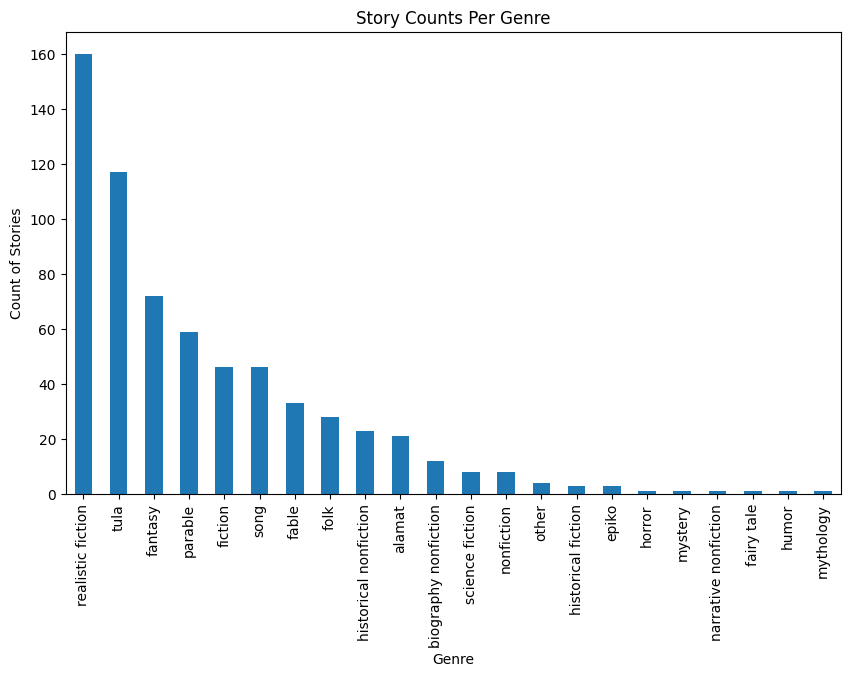

In [177]:
titles_genre['genre'].value_counts().plot(kind='bar', figsize=(10, 6))
plt.title('Story Counts Per Genre')
plt.xlabel('Genre')
plt.ylabel('Count of Stories')
plt.show()

## Merge genres with all text data

In [178]:
len(titles_genre['genre'].value_counts())

22

In [179]:
all_dfs = all_dfs.merge(titleslist[['filename', 'genre', 'genre_group']], how='left')
all_dfs

,filename,year_published,sentence_id,sentence,processed,genre,genre_group
0,2024PANANAGINIP SA TAG-ARAW.txt,2024,0,Gusto ko nang lumabas Dahil gusto ko na tumakb...,gusto ko nang lumabas dahil gusto ko na tumakb...,tula,traditional
1,2024PANANAGINIP SA TAG-ARAW.txt,2024,1,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...,tula,traditional
2,2024PANANAGINIP SA TAG-ARAW.txt,2024,2,Gusto ko nang lumabas Bago pa naman ang sapato...,gusto ko nang lumabas bago pa naman ang sapato...,tula,traditional
3,2024PANANAGINIP SA TAG-ARAW.txt,2024,3,May espesyal na ayuda ba sa mga natanggalan ng...,may espesyal na ayuda ba sa mga natanggalan ng...,tula,traditional
4,2024PANANAGINIP SA TAG-ARAW.txt,2024,4,"Gusto ko nang lumabas Sa bukid, magpalipad ng ...",gusto ko nang lumabas sa bukid magpalipad ng s...,tula,traditional
...,...,...,...,...,...,...,...
30573,Karapat-Dapat.txt,--,31736,"Dapat kang saklolohan kung ikaw ay nasaktan, n...",dapat kang saklolohan kung ikaw ay nasaktan na...,nonfiction,creative nonfiction
30574,Karapat-Dapat.txt,--,31737,May karapatan kang makatanggap ng tulong na le...,may karapatan kang makatanggap ng tulong na le...,nonfiction,creative nonfiction
30575,Karapat-Dapat.txt,--,31738,Kung ang mga batas sa iyong bansa ay nagkakalo...,kung ang mga batas sa iyong bansa ay nagkakalo...,nonfiction,creative nonfiction
30576,Karapat-Dapat.txt,--,31739,Karapatan mong alamin ang iyong mga karapatan!...,karapatan mong alamin ang iyong mga karapatan ...,nonfiction,creative nonfiction


## Remove rows with no genre

In [180]:
all_dfs = all_dfs.dropna(subset=['genre'])

In [181]:
all_dfs

,filename,year_published,sentence_id,sentence,processed,genre,genre_group
0,2024PANANAGINIP SA TAG-ARAW.txt,2024,0,Gusto ko nang lumabas Dahil gusto ko na tumakb...,gusto ko nang lumabas dahil gusto ko na tumakb...,tula,traditional
1,2024PANANAGINIP SA TAG-ARAW.txt,2024,1,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...,tula,traditional
2,2024PANANAGINIP SA TAG-ARAW.txt,2024,2,Gusto ko nang lumabas Bago pa naman ang sapato...,gusto ko nang lumabas bago pa naman ang sapato...,tula,traditional
3,2024PANANAGINIP SA TAG-ARAW.txt,2024,3,May espesyal na ayuda ba sa mga natanggalan ng...,may espesyal na ayuda ba sa mga natanggalan ng...,tula,traditional
4,2024PANANAGINIP SA TAG-ARAW.txt,2024,4,"Gusto ko nang lumabas Sa bukid, magpalipad ng ...",gusto ko nang lumabas sa bukid magpalipad ng s...,tula,traditional
...,...,...,...,...,...,...,...
30573,Karapat-Dapat.txt,--,31736,"Dapat kang saklolohan kung ikaw ay nasaktan, n...",dapat kang saklolohan kung ikaw ay nasaktan na...,nonfiction,creative nonfiction
30574,Karapat-Dapat.txt,--,31737,May karapatan kang makatanggap ng tulong na le...,may karapatan kang makatanggap ng tulong na le...,nonfiction,creative nonfiction
30575,Karapat-Dapat.txt,--,31738,Kung ang mga batas sa iyong bansa ay nagkakalo...,kung ang mga batas sa iyong bansa ay nagkakalo...,nonfiction,creative nonfiction
30576,Karapat-Dapat.txt,--,31739,Karapatan mong alamin ang iyong mga karapatan!...,karapatan mong alamin ang iyong mga karapatan ...,nonfiction,creative nonfiction


### Replace 'y with ay, 't with at, and hyphen with underscore

In [182]:
replacements = {
    "'y": " ay",
    "`y": " ay",
    "'Y": " ay",
    "`Y": " ay",
    "'t": " at",
    "`t": " at",
    "'T": " at",
    "`T": " at",
    "-": "_"
}
all_dfs['sentence'] = all_dfs['sentence'].str.replace("'y", " ay")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("`y", " ay")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("'Y", " ay")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("`Y", " ay")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("'t", " at")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("`t", " at")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("'T", " at")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("`T", " at")
all_dfs['sentence'] = all_dfs['sentence'].str.replace("-", "_")

In [183]:

all_dfs

,filename,year_published,sentence_id,sentence,processed,genre,genre_group
0,2024PANANAGINIP SA TAG-ARAW.txt,2024,0,Gusto ko nang lumabas Dahil gusto ko na tumakb...,gusto ko nang lumabas dahil gusto ko na tumakb...,tula,traditional
1,2024PANANAGINIP SA TAG-ARAW.txt,2024,1,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...,tula,traditional
2,2024PANANAGINIP SA TAG-ARAW.txt,2024,2,Gusto ko nang lumabas Bago pa naman ang sapato...,gusto ko nang lumabas bago pa naman ang sapato...,tula,traditional
3,2024PANANAGINIP SA TAG-ARAW.txt,2024,3,May espesyal na ayuda ba sa mga natanggalan ng...,may espesyal na ayuda ba sa mga natanggalan ng...,tula,traditional
4,2024PANANAGINIP SA TAG-ARAW.txt,2024,4,"Gusto ko nang lumabas Sa bukid, magpalipad ng ...",gusto ko nang lumabas sa bukid magpalipad ng s...,tula,traditional
...,...,...,...,...,...,...,...
30573,Karapat-Dapat.txt,--,31736,"Dapat kang saklolohan kung ikaw ay nasaktan, n...",dapat kang saklolohan kung ikaw ay nasaktan na...,nonfiction,creative nonfiction
30574,Karapat-Dapat.txt,--,31737,May karapatan kang makatanggap ng tulong na le...,may karapatan kang makatanggap ng tulong na le...,nonfiction,creative nonfiction
30575,Karapat-Dapat.txt,--,31738,Kung ang mga batas sa iyong bansa ay nagkakalo...,kung ang mga batas sa iyong bansa ay nagkakalo...,nonfiction,creative nonfiction
30576,Karapat-Dapat.txt,--,31739,Karapatan mong alamin ang iyong mga karapatan!...,karapatan mong alamin ang iyong mga karapatan ...,nonfiction,creative nonfiction


In [184]:
all_dfs[all_dfs['sentence'].str.contains('_')]

,filename,year_published,sentence_id,sentence,processed,genre,genre_group
1,2024PANANAGINIP SA TAG-ARAW.txt,2024,1,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...,tula,traditional
12,2024PANANAGINIP SA TAG-ARAW.txt,2024,12,Gusto ko nang lumabas Ako na ang pupuksa sa vi...,gusto ko nang lumabas ako na ang pupuksa sa vi...,tula,traditional
14,2024PANANAGINIP SA TAG-ARAW.txt,2024,14,Gusto ko na sanang lumabas Kahit hindi na sigu...,gusto ko na sanang lumabas kahit hindi na sigu...,tula,traditional
18,2009dyip.txt,2009,18,Ang lumang dyip ni Tatay ang kauna_unahang dyi...,ang lumang dyip ni tatay ang kauna-unahang dyi...,children’s picture books,fiction
19,2009dyip.txt,2009,19,Sinasabing walang taga_Pastol ang ‘di nakakiki...,sinasabing walang taga-pastol ang di nakakikil...,children’s picture books,fiction
...,...,...,...,...,...,...,...
30552,Karapat-Dapat.txt,--,31715,May karapatan ka sa proteksyon at tulong kung ...,may karapatan ka sa proteksyon at tulong kung ...,nonfiction,creative nonfiction
30561,Karapat-Dapat.txt,--,31724,Dapat din itong makatulong sa iyo na mabuhay n...,dapat din itong makatulong sa iyo na mabuhay n...,nonfiction,creative nonfiction
30565,Karapat-Dapat.txt,--,31728,May karapatan kang magkaroon ng proteksyon lab...,may karapatan kang magkaroon ng proteksyon lab...,nonfiction,creative nonfiction
30568,Karapat-Dapat.txt,--,31731,May karapatan kang maging ligtas mula sa pang_...,may karapatan kang maging ligtas mula sa pang-...,nonfiction,creative nonfiction


In [185]:
all_dfs.to_csv('tl_corpus_genre.csv', index=False)

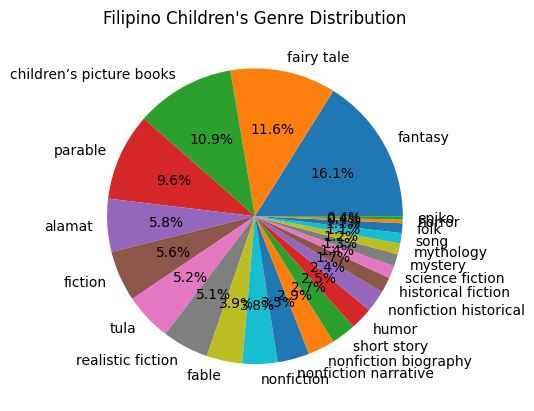

In [186]:
genre_count = all_dfs['genre'].value_counts()
plt.pie(genre_count, labels=genre_count.index, autopct='%1.1f%%')
plt.title("Filipino Children's Genre Distribution")
plt.show()

In [187]:
genre_count

genre
fantasy                     4924
fairy tale                  3534
children’s picture books    3322
parable                     2928
alamat                      1770
fiction                     1698
tula                        1594
realistic fiction           1551
fable                       1194
nonfiction                  1171
nonfiction narrative        1069
nonfiction biography         898
short story                  826
humor                        754
nonfiction historical        726
historical fiction           525
science fiction              417
mystery                      409
mythology                    362
song                         347
folk                         325
horror                       119
epiko                        115
Name: count, dtype: int64

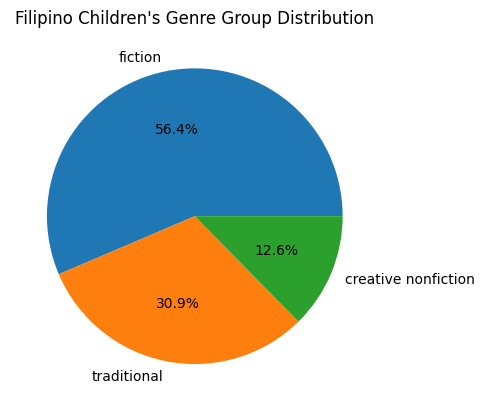

In [188]:
genre_grp_count = all_dfs['genre_group'].value_counts()
plt.pie(genre_grp_count, labels=genre_grp_count.index, autopct='%1.1f%%')
plt.title("Filipino Children's Genre Group Distribution")
plt.show()

In [189]:
genre_grp_count

genre_group
fiction                17253
traditional             9461
creative nonfiction     3864
Name: count, dtype: int64

In [190]:
titles_df

,filename
0,2024PANANAGINIP SA TAG-ARAW.txt
1,2023ANG PIPIT.txt
2,2009dyip.txt
3,2019sino_juan.txt
4,2024PAGDATING NG RASYON.txt
...,...
650,Munting Ningas-Apoy.txt
651,Apolinario Mabini (6-10).txt
652,Ang Pananakop ng mga Ingles (11-16).txt
653,Ang Agila at Ang Kalapati.txt


In [191]:
all_dfs[['filename','year_published', 'sentence', 'genre', 'genre_group']].to_csv('tl_original_data_v7.csv', index=False)
all_dfs[['filename','year_published', 'processed', 'genre', 'genre_group']].to_csv('tl_processed_data_v7.csv', index=False)

In [192]:
all_dfs

,filename,year_published,sentence_id,sentence,processed,genre,genre_group
0,2024PANANAGINIP SA TAG-ARAW.txt,2024,0,Gusto ko nang lumabas Dahil gusto ko na tumakb...,gusto ko nang lumabas dahil gusto ko na tumakb...,tula,traditional
1,2024PANANAGINIP SA TAG-ARAW.txt,2024,1,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...,tula,traditional
2,2024PANANAGINIP SA TAG-ARAW.txt,2024,2,Gusto ko nang lumabas Bago pa naman ang sapato...,gusto ko nang lumabas bago pa naman ang sapato...,tula,traditional
3,2024PANANAGINIP SA TAG-ARAW.txt,2024,3,May espesyal na ayuda ba sa mga natanggalan ng...,may espesyal na ayuda ba sa mga natanggalan ng...,tula,traditional
4,2024PANANAGINIP SA TAG-ARAW.txt,2024,4,"Gusto ko nang lumabas Sa bukid, magpalipad ng ...",gusto ko nang lumabas sa bukid magpalipad ng s...,tula,traditional
...,...,...,...,...,...,...,...
30573,Karapat-Dapat.txt,--,31736,"Dapat kang saklolohan kung ikaw ay nasaktan, n...",dapat kang saklolohan kung ikaw ay nasaktan na...,nonfiction,creative nonfiction
30574,Karapat-Dapat.txt,--,31737,May karapatan kang makatanggap ng tulong na le...,may karapatan kang makatanggap ng tulong na le...,nonfiction,creative nonfiction
30575,Karapat-Dapat.txt,--,31738,Kung ang mga batas sa iyong bansa ay nagkakalo...,kung ang mga batas sa iyong bansa ay nagkakalo...,nonfiction,creative nonfiction
30576,Karapat-Dapat.txt,--,31739,Karapatan mong alamin ang iyong mga karapatan!...,karapatan mong alamin ang iyong mga karapatan ...,nonfiction,creative nonfiction
